In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

In [4]:
csv_path = "../data/PRSA_Data_Aotizhongxin_20130301-20170228.csv"
df = pd.read_csv(csv_path)

df["timestamp"] = pd.to_datetime(
    df[["year", "month", "day", "hour"]]
)

df = df.sort_values("timestamp").reset_index(drop=True)

print(df.shape)

(35064, 19)


In [8]:
def create_sequences(dataframe, sequence_length=24):

    df = dataframe.sort_values("timestamp").reset_index(drop=True)

    X_list = []
    y_list = []
    target_times = []

    for i in range(len(df) - sequence_length):

        # Geçmiş 24 saat
        X = df["PM2.5"].iloc[i:i + sequence_length]

        # Bir sonraki saat
        y = df["PM2.5"].iloc[i + sequence_length]

        # Eksik değer kontrolü
        if X.isna().any() or pd.isna(y):
            continue

        # Zaman bilgileri
        times = df["timestamp"].iloc[i:i + sequence_length + 1]

        # Ardışık saat kontrolü
        time_diffs = times.diff().dropna()

        if not (time_diffs == pd.Timedelta(hours=1)).all():
            continue

        target_time = times.iloc[-1]

        # Verileri listelere ekle
        X_list.append(X.to_numpy().reshape(sequence_length, 1))
        y_list.append(y)
        target_times.append(target_time)

    # NumPy dönüşümü
    X_array = np.array(X_list, dtype=np.float32).reshape(-1, sequence_length, 1)
    y_array = np.array(y_list, dtype=np.float32)
    target_times = pd.DatetimeIndex(target_times)

    return X_array, y_array, target_times

In [9]:
X, y, target_times = create_sequences(
    df,
    sequence_length=24
)

print("X Shape:", X.shape)
print("y Shape:", y.shape)
print("Target Times:", len(target_times))

X Shape: (30062, 24, 1)
y Shape: (30062,)
Target Times: 30062


In [15]:
val_start_time = pd.Timestamp("2015-12-18 16:00")
test_start_time = pd.Timestamp("2016-07-24 20:00")

In [16]:
train_mask = target_times < val_start_time

val_mask = (
    (target_times >= val_start_time) &
    (target_times < test_start_time)
)

In [17]:
X_train_seq = X[train_mask]
y_train_seq = y[train_mask]

X_val_seq = X[val_mask]
y_val_seq = y[val_mask]

In [18]:
print("X Train:", X_train_seq.shape)
print("y Train:", y_train_seq.shape)

print("X Validation:", X_val_seq.shape)
print("y Validation:", y_val_seq.shape)

X Train: (21177, 24, 1)
y Train: (21177,)
X Validation: (4266, 24, 1)
y Validation: (4266,)


In [20]:
from sklearn.preprocessing import StandardScaler

input_scaler = StandardScaler()

X_train_scaled = input_scaler.fit_transform(
    X_train_seq.reshape(-1, 1)
)

X_val_scaled = input_scaler.transform(
    X_val_seq.reshape(-1, 1)
)

In [21]:
X_train_scaled = X_train_scaled.reshape(X_train_seq.shape)
X_val_scaled = X_val_scaled.reshape(X_val_seq.shape)

In [22]:
target_scaler = StandardScaler()

y_train_scaled = target_scaler.fit_transform(
    y_train_seq.reshape(-1, 1)
)

y_val_scaled = target_scaler.transform(
    y_val_seq.reshape(-1, 1)
)

In [23]:
print("X Train:", X_train_scaled.shape)
print("y Train:", y_train_scaled.shape)

print("X Validation:", X_val_scaled.shape)
print("y Validation:", y_val_scaled.shape)

X Train: (21177, 24, 1)
y Train: (21177, 1)
X Validation: (4266, 24, 1)
y Validation: (4266, 1)


In [24]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_scaled, dtype=torch.float32)

In [25]:
print(X_train_tensor.shape, X_train_tensor.dtype)
print(y_train_tensor.shape, y_train_tensor.dtype)

print(X_val_tensor.shape, X_val_tensor.dtype)
print(y_val_tensor.shape, y_val_tensor.dtype)

torch.Size([21177, 24, 1]) torch.float32
torch.Size([21177, 1]) torch.float32
torch.Size([4266, 24, 1]) torch.float32
torch.Size([4266, 1]) torch.float32


In [26]:
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))

Train: 21177
Validation: 4266


In [27]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

In [28]:
X_batch, y_batch = next(iter(train_loader))

print("X Batch:", X_batch.shape)
print("y Batch:", y_batch.shape)

X Batch: torch.Size([32, 24, 1])
y Batch: torch.Size([32, 1])


In [29]:
class AirPulseRNN(nn.Module):

    def __init__(self, input_size=1, hidden_size=32):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=1,
            hidden_size=32,
            num_layers=1,
            batch_first=True
        )

        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        output , hidden = self.rnn(x)

        last_output = output[: , -1 , :]

        prediction = self.fc(last_output)

        return prediction

In [30]:
sample = torch.randn(32, 24, 1)

model = AirPulseRNN()

output = model(sample)

print(output.shape)

torch.Size([32, 1])


In [32]:
torch.manual_seed(42)

model = AirPulseRNN()

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 10

In [33]:
def train_model(model, train_loader, val_loader,
                optimizer, criterion, epochs=10):

    train_losses = []
    val_losses = []

    for epoch in range(epochs):

        # TRAINING
        model.train()
        total_train_loss = 0.0

        for X_batch, y_batch in train_loader:

            optimizer.zero_grad()

            predictions = model(X_batch)

            loss = criterion(predictions, y_batch)

            loss.backward()

            optimizer.step()

            total_train_loss += loss.item()

        avg_train_loss = total_train_loss / len(train_loader)
        train_losses.append(avg_train_loss)

        # VALIDATION
        model.eval()
        total_val_loss = 0.0

        with torch.no_grad():

            for X_batch, y_batch in val_loader:

                predictions = model(X_batch)

                loss = criterion(predictions, y_batch)

                total_val_loss += loss.item()

        avg_val_loss = total_val_loss / len(val_loader)
        val_losses.append(avg_val_loss)

        # RESULTS
        print(f"Epoch {epoch + 1}/{epochs}")
        print(f"Train Loss: {avg_train_loss:.4f}")
        print(f"Validation Loss: {avg_val_loss:.4f}")
        print()

    return train_losses, val_losses

In [34]:
train_losses, val_losses = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer,
    criterion=criterion,
    epochs=10
)

Epoch 1/10
Train Loss: 0.2154
Validation Loss: 0.1558

Epoch 2/10
Train Loss: 0.0796
Validation Loss: 0.1032

Epoch 3/10
Train Loss: 0.0639
Validation Loss: 0.0846

Epoch 4/10
Train Loss: 0.0613
Validation Loss: 0.0805

Epoch 5/10
Train Loss: 0.0614
Validation Loss: 0.0793

Epoch 6/10
Train Loss: 0.0614
Validation Loss: 0.0785

Epoch 7/10
Train Loss: 0.0614
Validation Loss: 0.0779

Epoch 8/10
Train Loss: 0.0614
Validation Loss: 0.0774

Epoch 9/10
Train Loss: 0.0613
Validation Loss: 0.0770

Epoch 10/10
Train Loss: 0.0612
Validation Loss: 0.0765



In [ ]:

model.eval()


predictions_scaled = []

with torch.no_grad():

    for X_batch, y_batch in val_loader:

        predictions = model(X_batch)

        predictions_scaled.append(
            predictions.cpu().numpy()
        )

predictions_scaled = np.concatenate(predictions_scaled)


predictions_original = target_scaler.inverse_transform(
    predictions_scaled
)


rnn_mae = mean_absolute_error(
    y_val_seq,
    predictions_original.ravel()
)


rnn_rmse = np.sqrt(
    mean_squared_error(
        y_val_seq,
        predictions_original.ravel()
    )
)

# 8. Sonuçları göster
print(f"RNN Validation MAE: {rnn_mae:.2f}")
print(f"RNN Validation RMSE: {rnn_rmse:.2f}")

RNN Validation MAE: 10.66
RNN Validation RMSE: 21.14


In [36]:

naive_predictions = X_val_seq[:, -1, 0]

# MAE
naive_mae = mean_absolute_error(
    y_val_seq,
    naive_predictions
)

# RMSE
naive_rmse = np.sqrt(
    mean_squared_error(
        y_val_seq,
        naive_predictions
    )
)

print(f"Naive Validation MAE: {naive_mae:.2f}")
print(f"Naive Validation RMSE: {naive_rmse:.2f}")

Naive Validation MAE: 10.37
Naive Validation RMSE: 21.59


In [37]:

val_target_times = target_times[val_mask]

error_df = pd.DataFrame({
    "Hedef zamanı": val_target_times,
    "Gerçek PM2.5": y_val_seq,
    "RNN tahmini": predictions_original.ravel()
})


error_df["Mutlak hata"] = (
    error_df["Gerçek PM2.5"] - error_df["RNN tahmini"]
).abs()


top5_errors = error_df.nlargest(5, "Mutlak hata")

print(top5_errors.to_string(index=False))

       Hedef zamanı  Gerçek PM2.5  RNN tahmini  Mutlak hata
2016-02-08 02:00:00         898.0   466.940430   431.059570
2016-02-08 01:00:00         494.0   182.842087   311.157898
2016-02-08 09:00:00          37.0   308.375214   271.375214
2015-12-24 22:00:00         312.0    46.490601   265.509399
2016-03-09 14:00:00         270.0     8.314804   261.685181


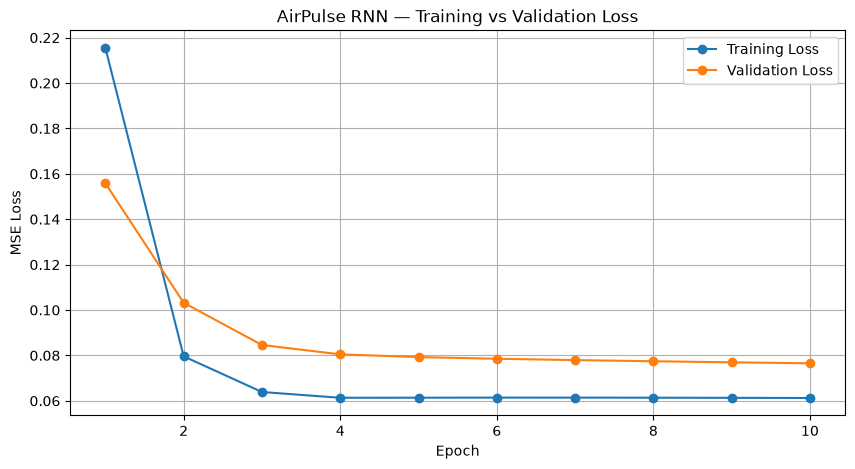

In [38]:
epochs_range = range(1, len(train_losses) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    train_losses,
    label="Training Loss",
    marker="o"
)

plt.plot(
    epochs_range,
    val_losses,
    label="Validation Loss",
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("AirPulse RNN — Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

In [39]:
val_target_times = target_times[val_mask]

start_time = val_target_times[0]
end_time = start_time + pd.Timedelta(days=3)

time_mask = (
    (val_target_times >= start_time) &
    (val_target_times < end_time)
)

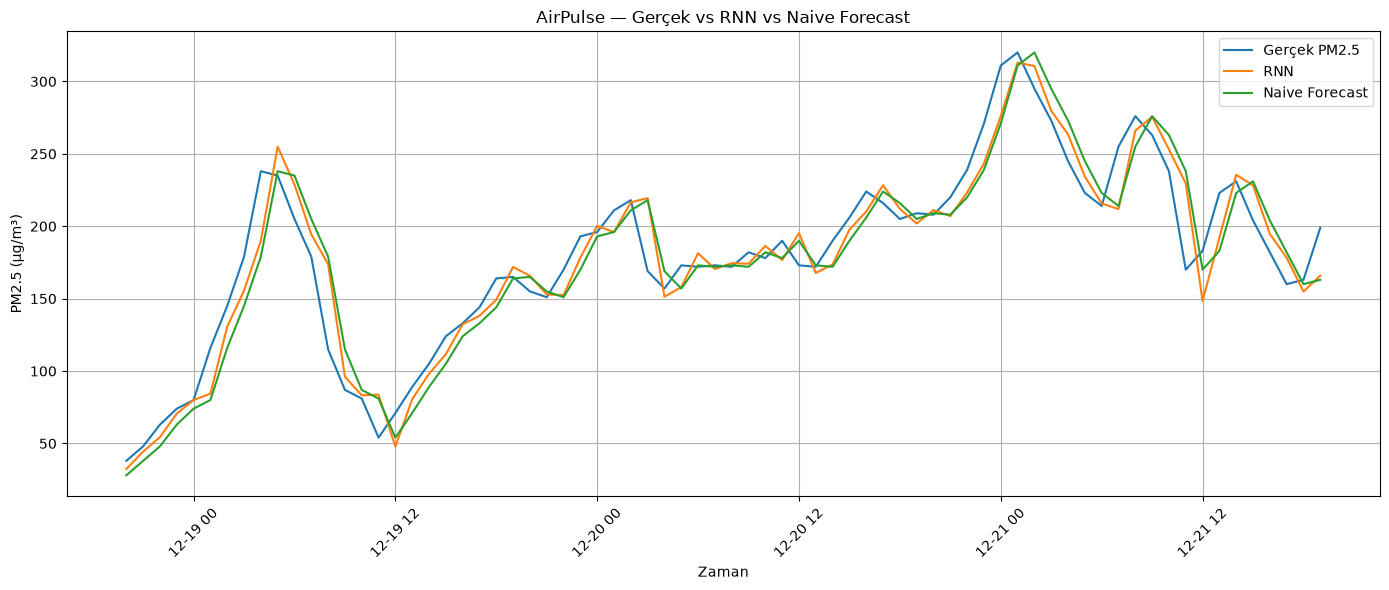

In [40]:
plt.figure(figsize=(14, 6))

plt.plot(
    val_target_times[time_mask],
    y_val_seq[time_mask],
    label="Gerçek PM2.5"
)

plt.plot(
    val_target_times[time_mask],
    predictions_original.ravel()[time_mask],
    label="RNN"
)

plt.plot(
    val_target_times[time_mask],
    naive_predictions[time_mask],
    label="Naive Forecast"
)

plt.xlabel("Zaman")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("AirPulse — Gerçek vs RNN vs Naive Forecast")

plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [41]:
assert X_train_tensor.ndim == 3

assert X_train_tensor.shape[1] == 24

print("✅ Test 1 başarılı: Sequence Shape doğru.")

✅ Test 1 başarılı: Sequence Shape doğru.


In [42]:
# TEST 2 — Zaman bütünlüğü


sorted_times = df.sort_values("timestamp")["timestamp"].to_numpy()

target_positions = pd.Index(sorted_times).get_indexer(target_times)

assert (target_positions >= 24).all()

offsets = np.arange(24, -1, -1)

window_times = sorted_times[
    target_positions[:, None] - offsets
]

time_differences = np.diff(window_times, axis=1)

assert np.all(time_differences == np.timedelta64(1, "h"))

print("✅ Test 2 başarılı: Tüm pencereler saatlik olarak ardışık.")

✅ Test 2 başarılı: Tüm pencereler saatlik olarak ardışık.


In [43]:
# TEST 3 — Data Leakage

train_target_times = target_times[train_mask]
val_target_times = target_times[val_mask]


assert train_target_times.max() < val_target_times.min()


val_last_input_times = window_times[val_mask, -2]


assert np.all(
    val_last_input_times < val_target_times.to_numpy()
)

assert np.all(
    val_target_times.to_numpy() - val_last_input_times
    == np.timedelta64(1, "h")
)

print("✅ Test 3 başarılı: Zaman bazlı veri sızıntısı tespit edilmedi.")

✅ Test 3 başarılı: Zaman bazlı veri sızıntısı tespit edilmedi.


In [44]:
error_df = pd.DataFrame({
    "Hedef zamanı": target_times[val_mask],
    "Gerçek PM2.5": y_val_seq,
    "RNN tahmini": predictions_original.ravel()
})

error_df["Mutlak hata"] = (
    error_df["Gerçek PM2.5"] - error_df["RNN tahmini"]
).abs()

top5_errors = error_df.nlargest(5, "Mutlak hata")

display(top5_errors)

,Hedef zamanı,Gerçek PM2.5,RNN tahmini,Mutlak hata
1053,2016-02-08 02:00:00,898.0,466.940430,431.059570
1052,2016-02-08 01:00:00,494.0,182.842087,311.157898
1060,2016-02-08 09:00:00,37.0,308.375214,271.375214
121,2015-12-24 22:00:00,312.0,46.490601,265.509399
1683,2016-03-09 14:00:00,270.0,8.314804,261.685181


In [45]:

from pathlib import Path

# reports klasörünü belirle
reports_dir = (
    Path("../reports")
    if Path.cwd().name == "notebooks"
    else Path("reports")
)

reports_dir.mkdir(parents=True, exist_ok=True)

# Model sonuçları
results = pd.DataFrame([{
    "model": type(model).__name__,
    "sequence_length": X_train_tensor.shape[1],
    "hidden_size": model.rnn.hidden_size,
    "epochs": len(train_losses),
    "learning_rate": optimizer.param_groups[0]["lr"],
    "train_loss": train_losses[-1],
    "validation_loss": val_losses[-1],
    "mae": rnn_mae,
    "rmse": rnn_rmse
}])

# CSV dosyasını kaydet
csv_path = reports_dir / "rnn_baseline.csv"

results.to_csv(csv_path, index=False)

print(f"CSV oluşturuldu: {csv_path.resolve()}")

display(results)

CSV oluşturuldu: /home/pasali/Desktop/Data/AI-Engineer/Hafta-3/AirPulse/reports/rnn_baseline.csv


,model,sequence_length,hidden_size,epochs,learning_rate,train_loss,validation_loss,mae,rmse
0,AirPulseRNN,24,32,10,0.001,0.061239,0.076528,10.66174,21.143754
